In [1]:
# Import needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


In [2]:
# Load prediction results
ukf_results = pd.read_csv("UKF_pred_results.csv")
ukf_results.info()


<class 'pandas.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Delay_ms           119 non-null    int64  
 1   Joint              119 non-null    str    
 2   UKF_RMSE_rad       119 non-null    float64
 3   Baseline_RMSE_rad  119 non-null    float64
 4   Improvement_%      102 non-null    float64
dtypes: float64(3), int64(1), str(1)
memory usage: 4.8 KB


In [3]:
# # Convert index to string, append '1', and convert back to integer
# ukf_results['Delay_ms'] = (ukf_results['Delay_ms'].astype(str) + '1').astype(int)

# # View the updated dataframe
# # display(mean_rmse)
# ukf_results.head()

In [4]:
ukf_results = ukf_results.dropna()
ukf_results.head()

,Delay_ms,Joint,UKF_RMSE_rad,Baseline_RMSE_rad,Improvement_%
0,10,shoulder_pan_joint,0.016659,0.033623,50.5
1,10,shoulder_lift_joint,0.014309,0.031658,54.8
2,10,elbow_joint,0.016859,0.031432,46.4
3,10,wrist_1_joint,0.015852,0.031818,50.2
4,10,wrist_2_joint,0.016164,0.031331,48.4


In [5]:
ukf_results = ukf_results.copy()
ukf_results['estimation_Error'] = ukf_results['Baseline_RMSE_rad'] - ukf_results['UKF_RMSE_rad']
ukf_results.head()

,Delay_ms,Joint,UKF_RMSE_rad,Baseline_RMSE_rad,Improvement_%,estimation_Error
0,10,shoulder_pan_joint,0.016659,0.033623,50.5,0.016964
1,10,shoulder_lift_joint,0.014309,0.031658,54.8,0.017349
2,10,elbow_joint,0.016859,0.031432,46.4,0.014573
3,10,wrist_1_joint,0.015852,0.031818,50.2,0.015966
4,10,wrist_2_joint,0.016164,0.031331,48.4,0.015167


In [6]:
ukf_results["Improvement_%"] = ((ukf_results["Baseline_RMSE_rad"] - ukf_results["UKF_RMSE_rad"]) / ukf_results["Baseline_RMSE_rad"]) * 100
ukf_results[60:]

,Delay_ms,Joint,UKF_RMSE_rad,Baseline_RMSE_rad,Improvement_%,estimation_Error
70,1500,shoulder_pan_joint,0.496887,0.544062,8.670887,0.047175
71,1500,shoulder_lift_joint,0.286364,0.305372,6.224539,0.019008
72,1500,elbow_joint,0.529112,0.579926,8.762152,0.050814
73,1500,wrist_1_joint,0.411296,0.423096,2.788965,0.011800
74,1500,wrist_2_joint,0.512034,0.489697,-4.561392,-0.022337
75,1500,wrist_3_joint,0.534880,0.579165,7.646353,0.044285
77,2000,shoulder_pan_joint,0.622221,0.655505,5.077612,0.033284
78,2000,shoulder_lift_joint,0.352872,0.370035,4.638210,0.017163
79,2000,elbow_joint,0.665758,0.702047,5.169027,0.036289
80,2000,wrist_1_joint,0.499377,0.482321,-3.536234,-0.017056


In [7]:
ukf_results[:60]

,Delay_ms,Joint,UKF_RMSE_rad,Baseline_RMSE_rad,Improvement_%,estimation_Error
0,10,shoulder_pan_joint,0.016659,0.033623,50.453559,0.016964
1,10,shoulder_lift_joint,0.014309,0.031658,54.801314,0.017349
2,10,elbow_joint,0.016859,0.031432,46.363579,0.014573
3,10,wrist_1_joint,0.015852,0.031818,50.179144,0.015966
4,10,wrist_2_joint,0.016164,0.031331,48.408924,0.015167
5,10,wrist_3_joint,0.016682,0.033868,50.744065,0.017186
7,50,shoulder_pan_joint,0.022449,0.041501,45.907328,0.019052
8,50,shoulder_lift_joint,0.018215,0.034656,47.440559,0.016441
9,50,elbow_joint,0.024391,0.042365,42.426531,0.017974
10,50,wrist_1_joint,0.020951,0.036304,42.290106,0.015353


In [8]:
ukf_results["Delay_ms"].sort_values().unique()

array([  10,   50,  100,  300,  500,  700,  900, 1100, 1200, 1300, 1500,
       2000, 2500, 3000, 3500, 4500, 5000])

In [9]:
# Calculate the mean RMSE
mean_rmse = ukf_results.groupby("Delay_ms")[["UKF_RMSE_rad", "Baseline_RMSE_rad"]].mean()
# Calculate improvement percentage: ((Baseline - UKF) / Baseline) * 100
mean_rmse["Improvement_%"] = ((mean_rmse["Baseline_RMSE_rad"] - mean_rmse["UKF_RMSE_rad"]) / mean_rmse["Baseline_RMSE_rad"]) * 100
mean_rmse.info()

<class 'pandas.DataFrame'>
Index: 17 entries, 10 to 5000
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   UKF_RMSE_rad       17 non-null     float64
 1   Baseline_RMSE_rad  17 non-null     float64
 2   Improvement_%      17 non-null     float64
dtypes: float64(3)
memory usage: 544.0 bytes


In [10]:
# View mean RMSE values
mean_rmse

,UKF_RMSE_rad,Baseline_RMSE_rad,Improvement_%
Delay_ms,,,
10,0.016088,0.032288,50.175502
50,0.022025,0.039698,44.518196
100,0.031569,0.054721,42.308911
300,0.083959,0.130828,35.824691
500,0.141205,0.197863,28.635145
700,0.218156,0.276901,21.215129
900,0.292932,0.344770,15.035449
1100,0.362949,0.408692,11.192577
1200,0.391789,0.431513,9.205780


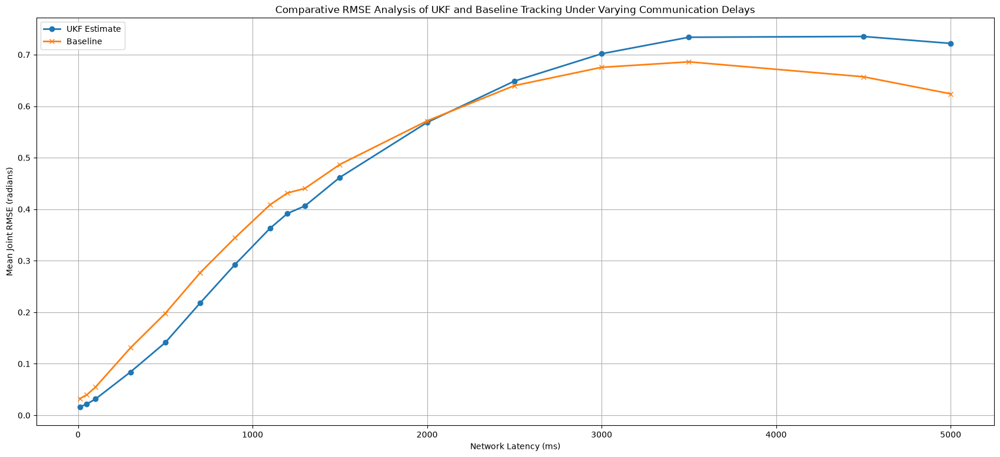

In [11]:
# RMSE vs. Latency Plot
plt.figure(figsize=(21, 9))

# Added thicker lines and clearer labels for the legend
plt.plot(mean_rmse.index, mean_rmse['UKF_RMSE_rad'], marker='o', linewidth=2, label='UKF Estimate')
plt.plot(mean_rmse.index, mean_rmse['Baseline_RMSE_rad'], marker='x', linewidth=2, label='Baseline')

plt.xlabel('Network Latency (ms)')
plt.ylabel('Mean Joint RMSE (radians)')
plt.title("Comparative RMSE Analysis of UKF and Baseline Tracking Under Varying Communication Delays")
plt.grid(True)
plt.legend()
plt.show()

In [12]:
# FORMATTING FOR LATEX

# Force RMSE columns to exactly 4 decimal places
mean_rmse["UKF_RMSE_rad"] = mean_rmse["UKF_RMSE_rad"].map("{:.4f}".format)
mean_rmse["Baseline_RMSE_rad"] = mean_rmse["Baseline_RMSE_rad"].map("{:.4f}".format)

# Format improvement as a percentage with 1 decimal place
mean_rmse["Improvement_%"] = mean_rmse["Improvement_%"].map("{:.2f}".format)

# Display the updated dataframe
mean_rmse

,UKF_RMSE_rad,Baseline_RMSE_rad,Improvement_%
Delay_ms,,,
10,0.0161,0.0323,50.18
50,0.0220,0.0397,44.52
100,0.0316,0.0547,42.31
300,0.0840,0.1308,35.82
500,0.1412,0.1979,28.64
700,0.2182,0.2769,21.22
900,0.2929,0.3448,15.04
1100,0.3629,0.4087,11.19
1200,0.3918,0.4315,9.21


# NIS Analysis

In [13]:
# Load the NIS results
nis_df = pd.read_csv("UKF_nis_results.csv", index_col=0)
nis_df.head(8)

,Channel,Mean_NIS,Frac_Within_95CI
Delay_ms,,,
10,shoulder_pan_joint,0.9622,0.952
10,shoulder_lift_joint,0.9257,0.954
10,elbow_joint,0.9827,0.954
10,wrist_1_joint,0.9446,0.953
10,wrist_2_joint,0.9410,0.950
10,wrist_3_joint,0.9781,0.950
10,TOTAL_6DOF,5.7343,0.951
50,shoulder_pan_joint,0.9633,0.949


In [14]:
nis_df.info()

<class 'pandas.DataFrame'>
Index: 119 entries, 10 to 5000
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Channel           119 non-null    str    
 1   Mean_NIS          119 non-null    float64
 2   Frac_Within_95CI  119 non-null    float64
dtypes: float64(2), str(1)
memory usage: 3.7 KB


In [15]:
# Filter for the Total 6-DOF state and sort by latency
total_nis = nis_df[nis_df['Channel'] == 'TOTAL_6DOF'].sort_values('Delay_ms')
total_nis

,Channel,Mean_NIS,Frac_Within_95CI
Delay_ms,,,
10,TOTAL_6DOF,5.7343,0.951
50,TOTAL_6DOF,5.7594,0.958
100,TOTAL_6DOF,5.7603,0.956
300,TOTAL_6DOF,5.7276,0.954
500,TOTAL_6DOF,5.8037,0.949
700,TOTAL_6DOF,5.7385,0.954
900,TOTAL_6DOF,5.7087,0.948
1100,TOTAL_6DOF,5.7680,0.947
1200,TOTAL_6DOF,5.7594,0.950


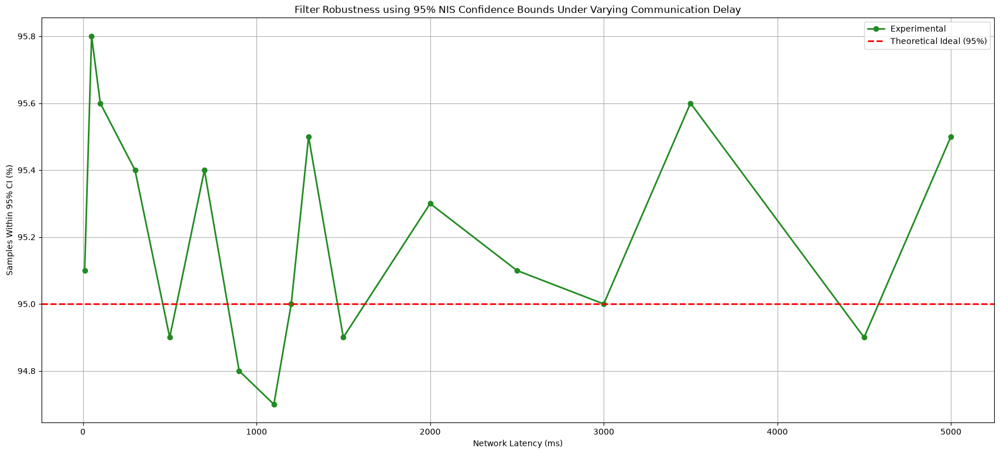

In [16]:
# Filter Consistency by Latency

plt.figure(figsize=(21, 9))
plt.plot(total_nis.index, total_nis['Frac_Within_95CI'] * 100, marker='o', color='forestgreen', linewidth=2, label='Experimental')
plt.axhline(y=95.0, color='red', linestyle='--', linewidth=2, label='Theoretical Ideal (95%)')
plt.xlabel('Network Latency (ms)')
plt.ylabel('Samples Within 95% CI (%)')
plt.title('Filter Robustness using 95% NIS Confidence Bounds Under Varying Communication Delay')
plt.grid(True)
plt.legend()
plt.show()

In [17]:
# FORMATTING FOR LATEX

# Format Frac_Within_95CI as a percentage with 1 decimal place
total_nis["Frac_Within_95CI_%"] = (total_nis["Frac_Within_95CI"]* 100).map("{:.2f}".format)
total_nis = total_nis.drop(columns=["Frac_Within_95CI", "Channel"])

# Display the updated dataframe
total_nis

,Mean_NIS,Frac_Within_95CI_%
Delay_ms,,
10,5.7343,95.10
50,5.7594,95.80
100,5.7603,95.60
300,5.7276,95.40
500,5.8037,94.90
700,5.7385,95.40
900,5.7087,94.80
1100,5.7680,94.70
1200,5.7594,95.00


In [22]:
JOINT_NAMES = [
    'shoulder_pan_joint',
    'shoulder_lift_joint',
    'elbow_joint',
    'wrist_1_joint',
    'wrist_2_joint',
    'wrist_3_joint',
    ]
# Dictionary to translate raw code names to friendly names
clean_NAMES = {
    'shoulder_pan_joint': 'Joint 1',
    'shoulder_lift_joint': 'Joint 2',
    'elbow_joint': 'Joint 3',
    'wrist_1_joint': 'Joint 4',
    'wrist_2_joint': 'Joint 5',
    'wrist_3_joint': 'Joint 6',
}

In [23]:
def traject_tracking(delay_scenario, joint_name):
    # 1. Create a NEW variable for the clean name, don't overwrite 'joint_name'
    clean_joint_name = clean_NAMES.get(joint_name, joint_name) 
    
    file_path = f"UKF_timeseries_plot/{delay_scenario}ms.csv"

    # Load the data
    df = pd.read_csv(file_path)

    # 2. Use the ORIGINAL 'joint_name' (e.g., base_link_to_link1) to extract data
    t = df['time_sec']
    true_pos = df[f'{joint_name}_true']
    del_pos = df[f'{joint_name}_delayed']
    pred_pos = df[f'{joint_name}_pred']

    # Calculate absolute errors
    error_baseline = np.abs(true_pos - del_pos)
    error_ukf = np.abs(true_pos - pred_pos)

    # Plotting Setup (Academic Style)
    plt.rcParams.update({'font.size': 12, 'font.family': 'sans-serif'})

    # PLOT 1: Trajectory Tracking
    fig1, ax1 = plt.subplots(figsize=(10, 4), dpi=300) 

    ax1.plot(t, true_pos, label='Ground Truth', color='black', linestyle='--', linewidth=2, zorder=3)
    # Added 'ms' to the label for proper units
    ax1.plot(t, del_pos, label=f'Delayed ({delay_scenario} ms)', color='red', alpha=0.6, linewidth=1.5)
    ax1.plot(t, pred_pos, label='UKF Predicted', color='blue', linewidth=2, zorder=2)

    ax1.set_xlabel('Time (seconds)', fontweight='bold') 
    
    # 3. Use the CLEAN name for plot text
    ax1.set_ylabel(f'{clean_joint_name} Position (rad)', fontweight='bold')
    
    # Kept the titles for you, but updated them to use the clean name and proper units
    ax1.set_title(f'UKF Latency Compensation on {clean_joint_name} ({delay_scenario} ms Delay)', fontweight='bold')
    
    ax1.legend(loc='upper right')
    ax1.grid(True, linestyle=':', alpha=0.7)

    plt.tight_layout()
    plt.show()

    # PLOT 2: Absolute Error Comparison
    fig2, ax2 = plt.subplots(figsize=(10, 4), dpi=300)

    ax2.plot(t, error_baseline, label='Baseline Error (Delayed)', color='red', alpha=0.6, linewidth=1.5)
    ax2.plot(t, error_ukf, label='UKF Error', color='blue', linewidth=1.5)

    ax2.set_xlabel('Time (seconds)', fontweight='bold')
    
    # Use the CLEAN name here, and remove the duplicate ylabel command
    ax2.set_ylabel(f'{clean_joint_name} Absolute Error (rad)', fontweight='bold')
    ax2.set_title(f'Error Comparison on {clean_joint_name}', fontweight='bold') 
    
    ax2.legend(loc='upper right')
    ax2.grid(True, linestyle=':', alpha=0.7)

    # Highlight the improvement zone visually
    ax2.fill_between(t, error_ukf, error_baseline, where=(error_baseline > error_ukf), 
                    facecolor='green', alpha=0.1, interpolate=True, label='Error Reduced')

    plt.tight_layout()
    plt.show()

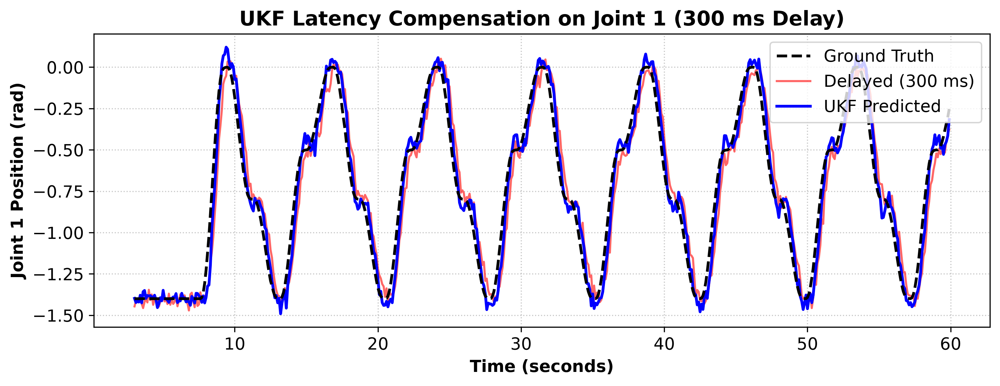

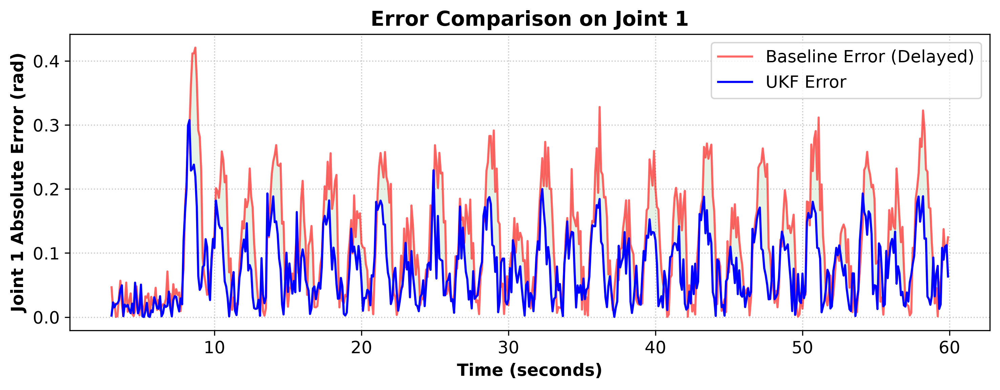

In [24]:
# Call the function
traject_tracking("300", JOINT_NAMES[0])

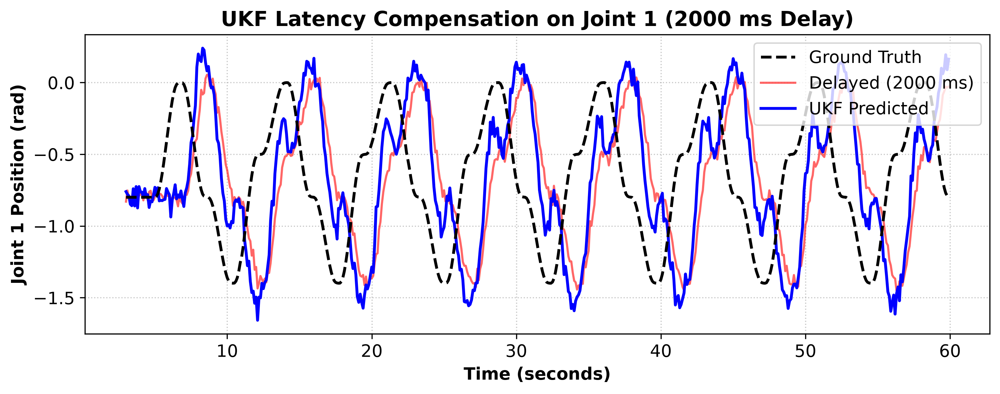

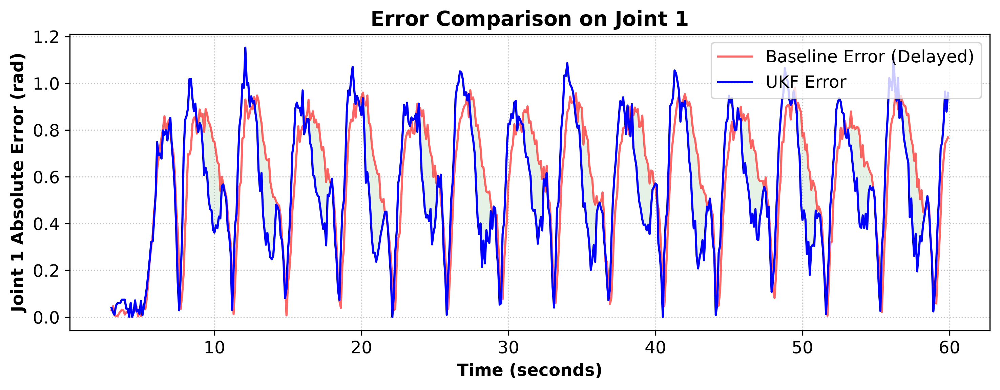

In [25]:
# Call the function
traject_tracking("2000", JOINT_NAMES[0])

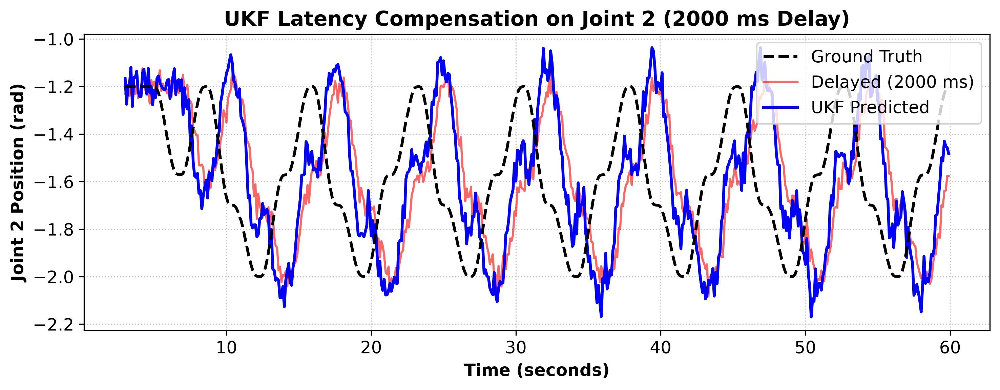

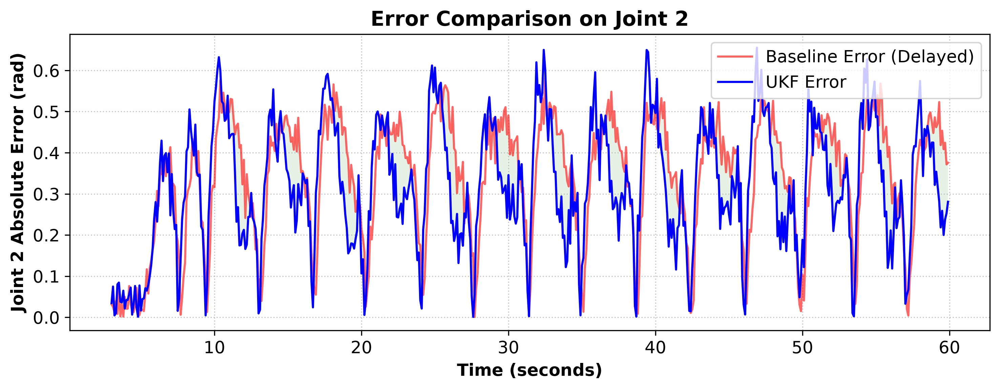

In [26]:
# Call the function
traject_tracking("2000", JOINT_NAMES[1])

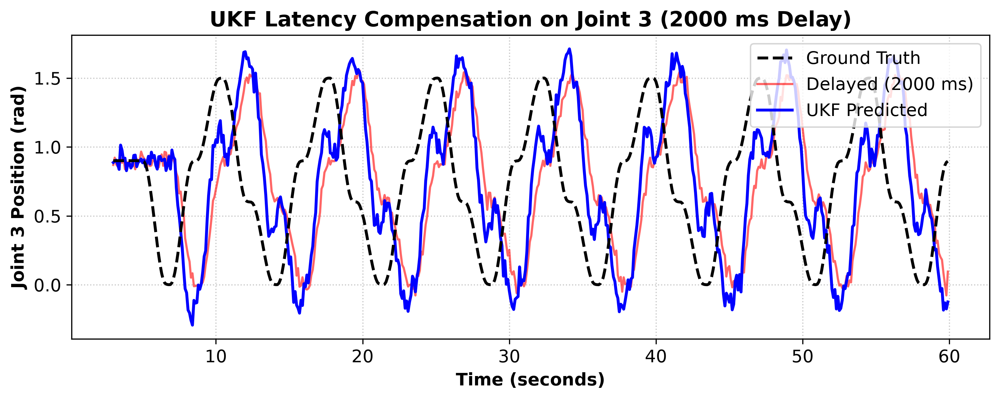

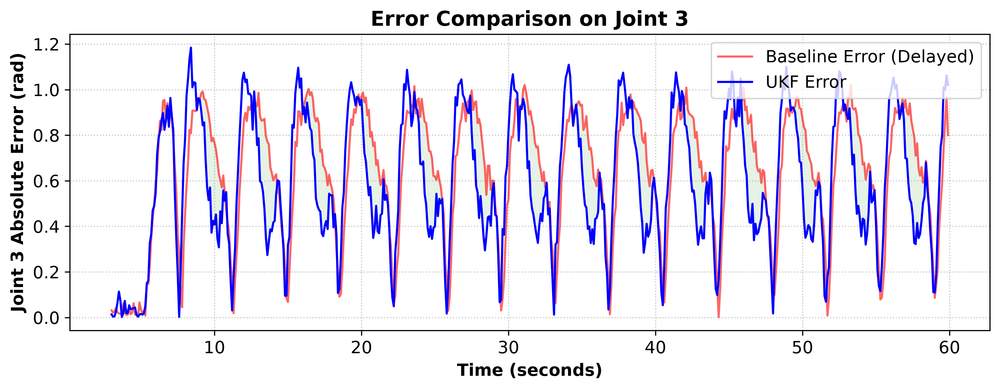

In [27]:
# Call the function
traject_tracking("2000", JOINT_NAMES[2])

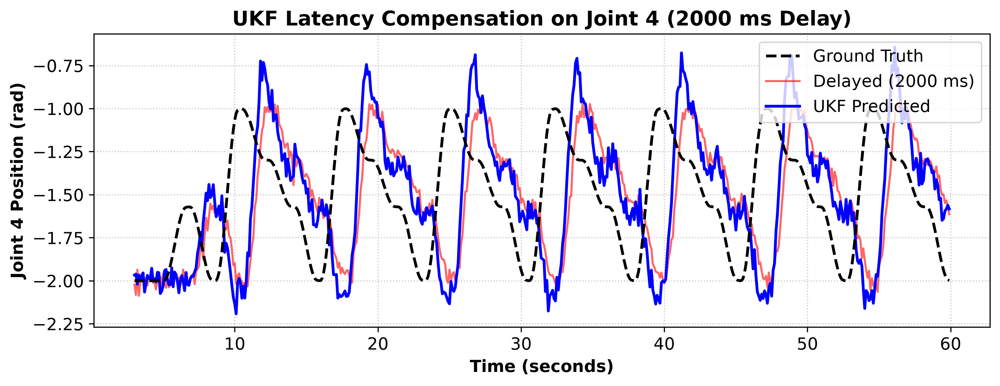

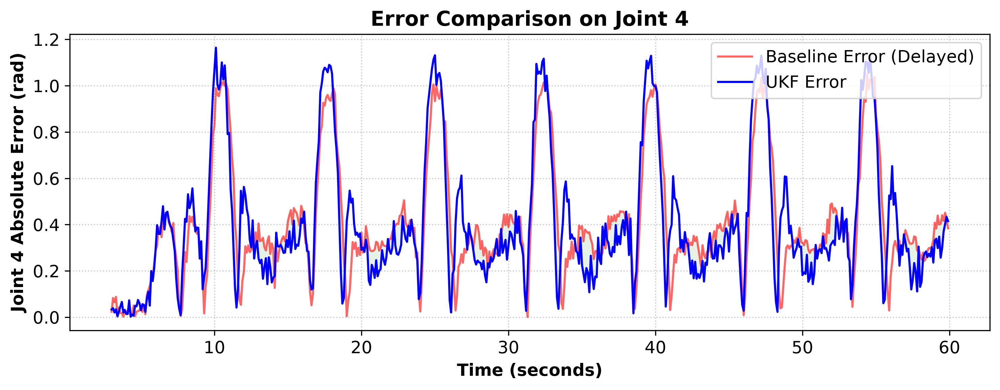

In [28]:
# Call the function
traject_tracking("2000", JOINT_NAMES[3])

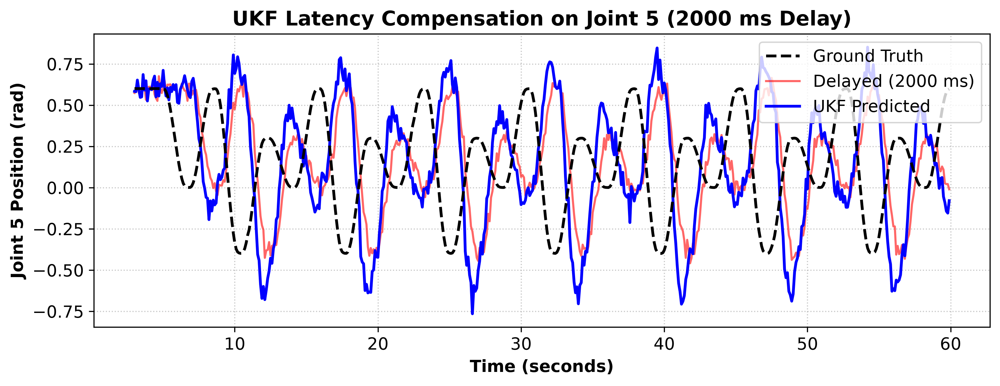

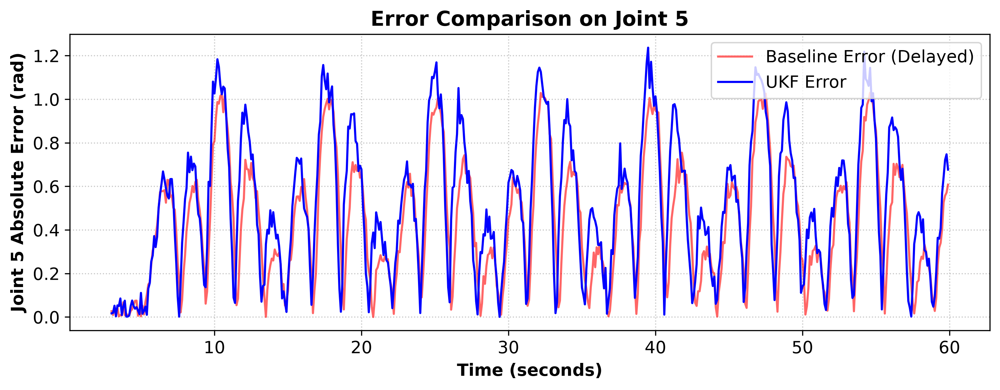

In [29]:
# Call the function
traject_tracking("2000", JOINT_NAMES[4])

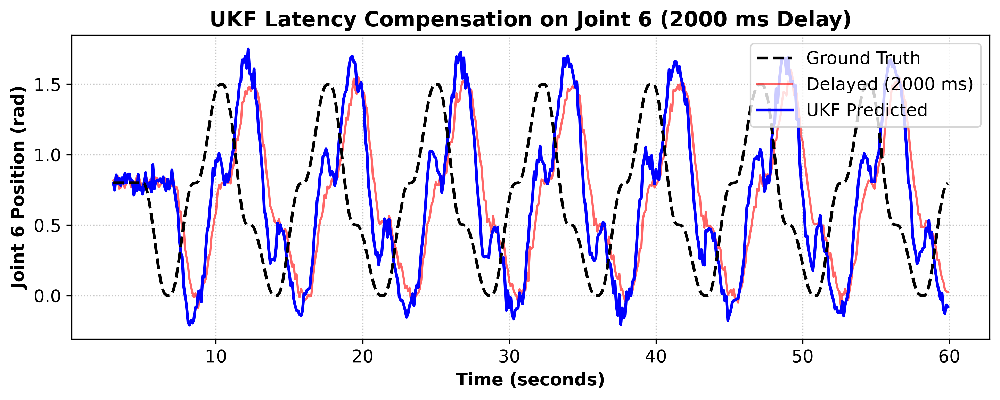

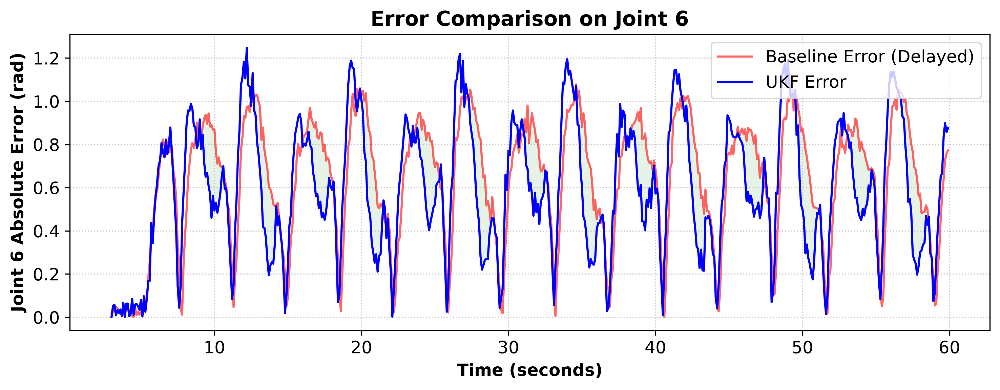

In [30]:
# Call the function
traject_tracking("2000", JOINT_NAMES[5])

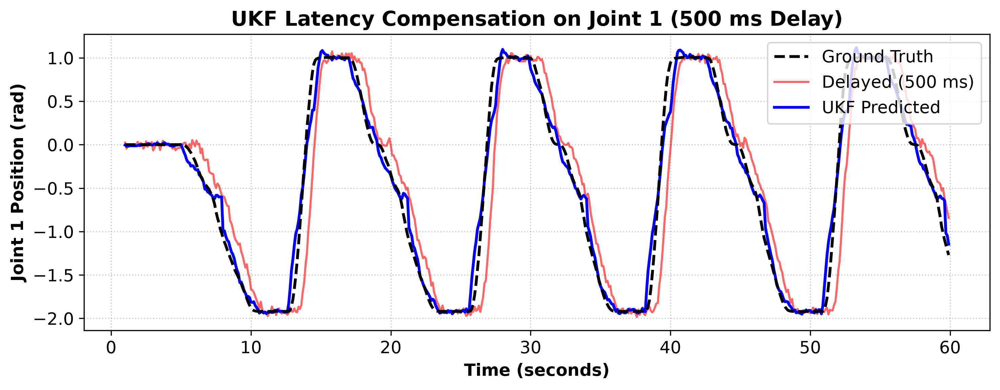

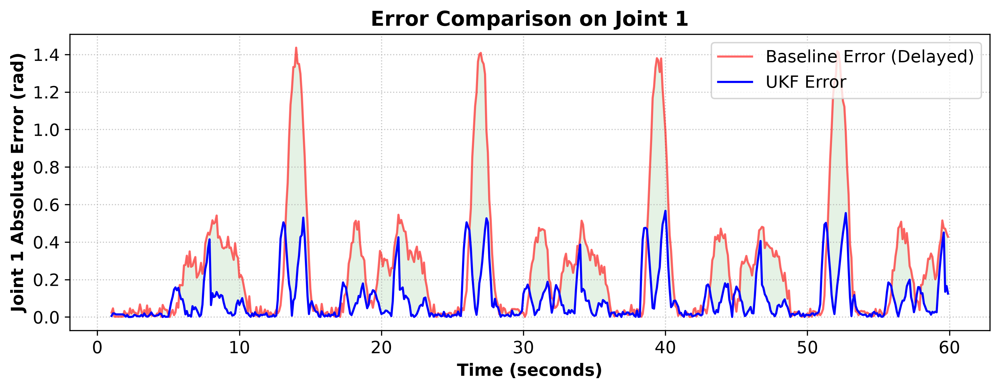

In [ ]:
# Call the function
traject_tracking("500", JOINT_NAMES[0])

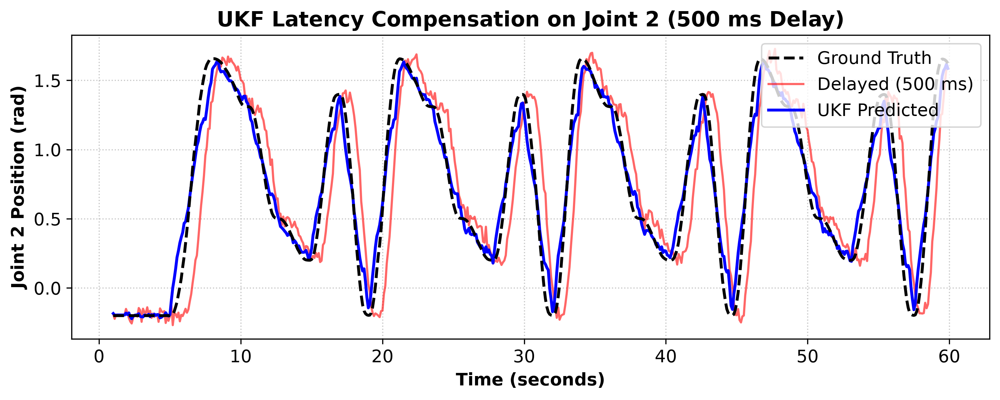

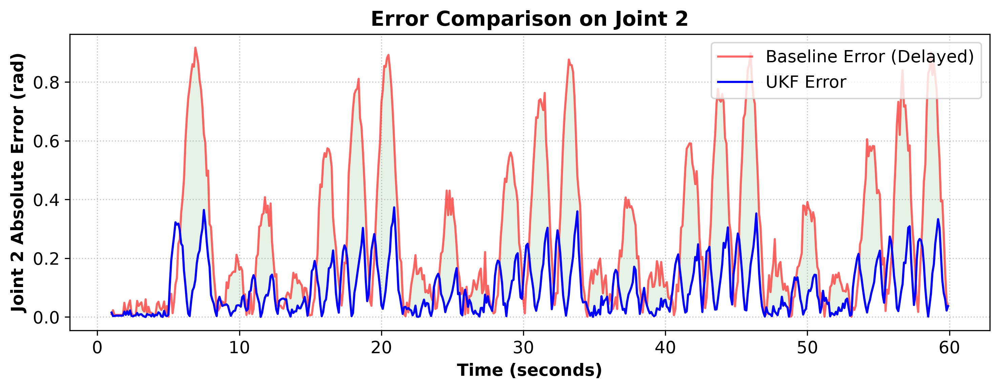

In [ ]:
# Call the function
traject_tracking("500", JOINT_NAMES[1])

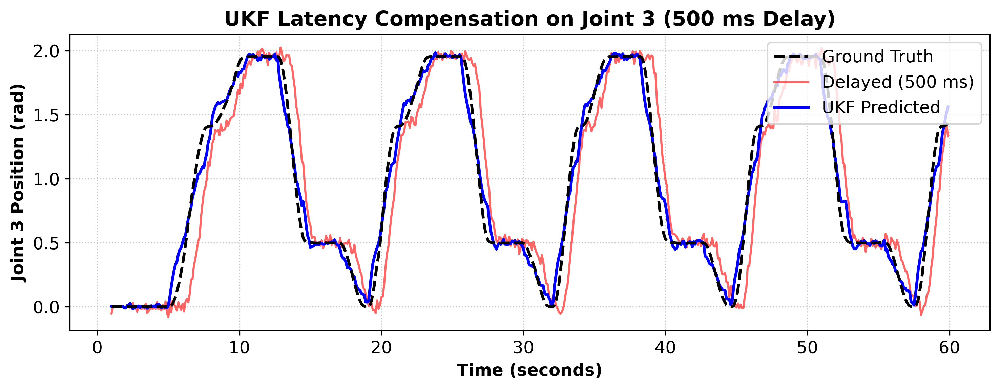

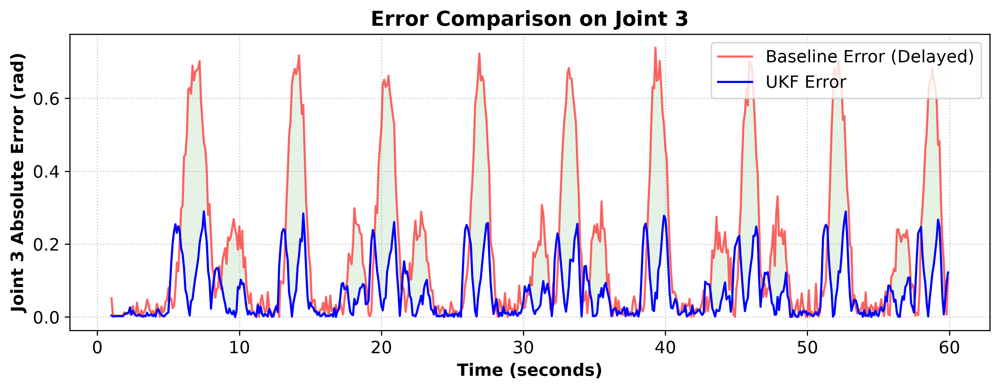

In [ ]:
# Call the function
traject_tracking("500", JOINT_NAMES[2])

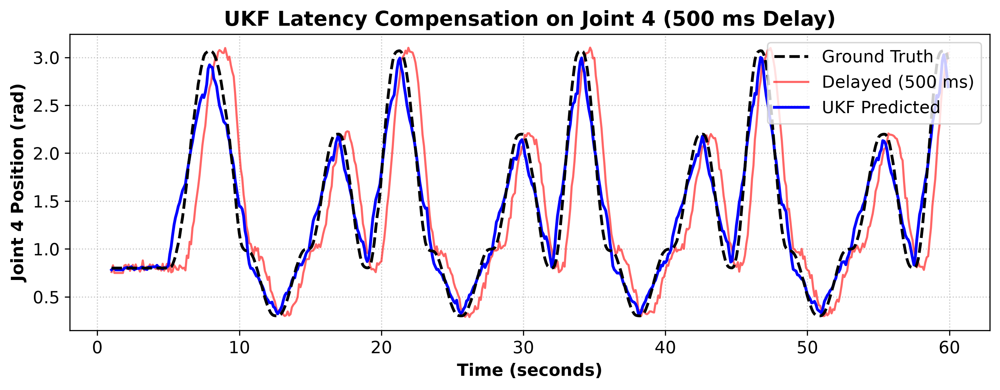

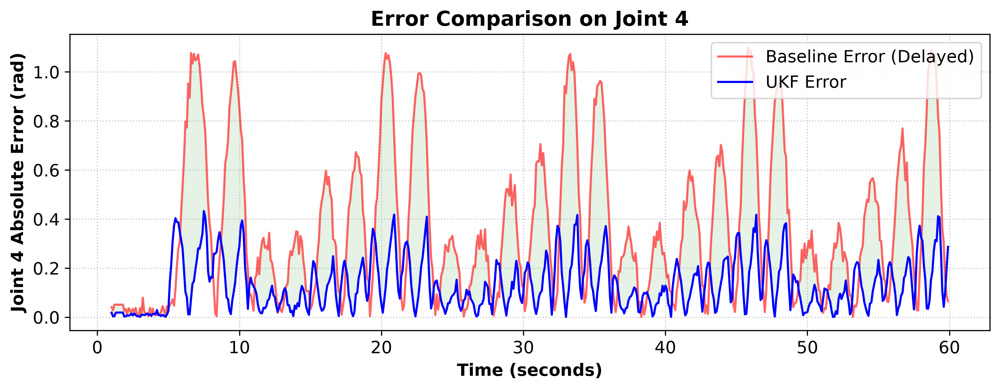

In [ ]:
# Call the function
traject_tracking("500", JOINT_NAMES[3])

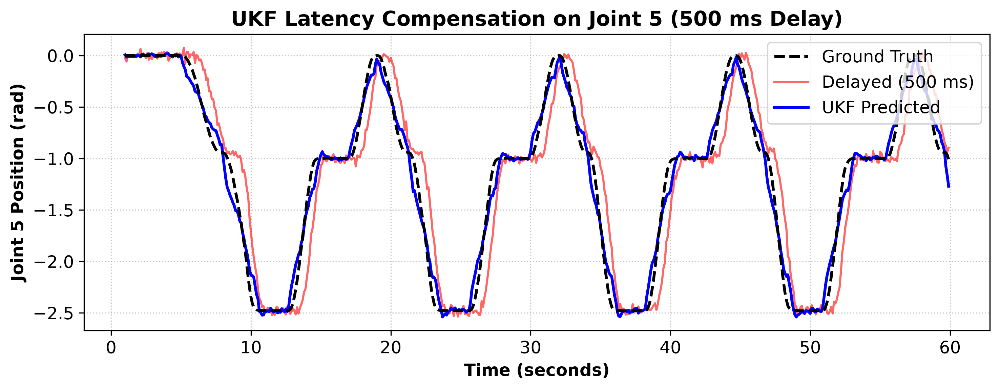

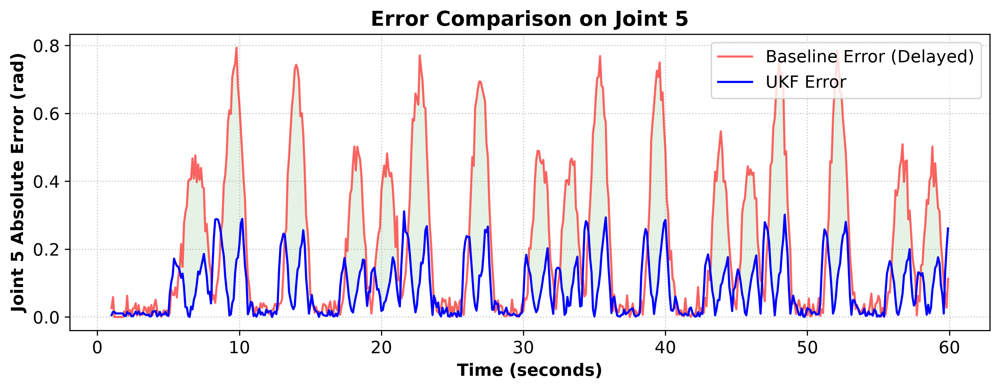

In [ ]:
# Call the function
traject_tracking("500", JOINT_NAMES[4])

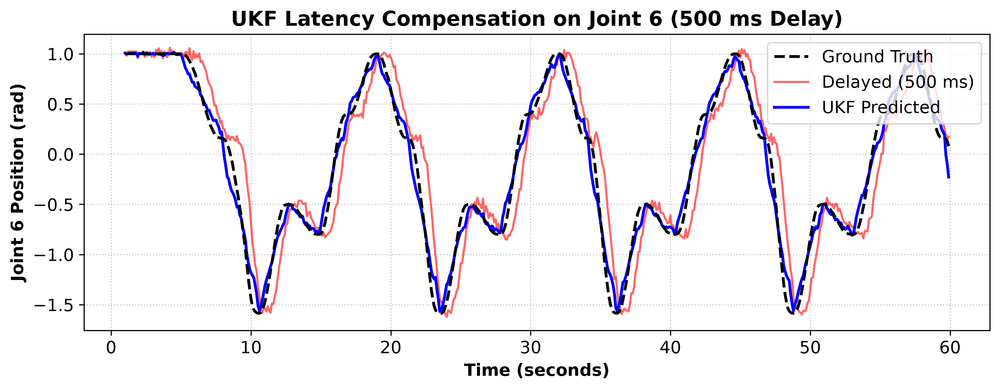

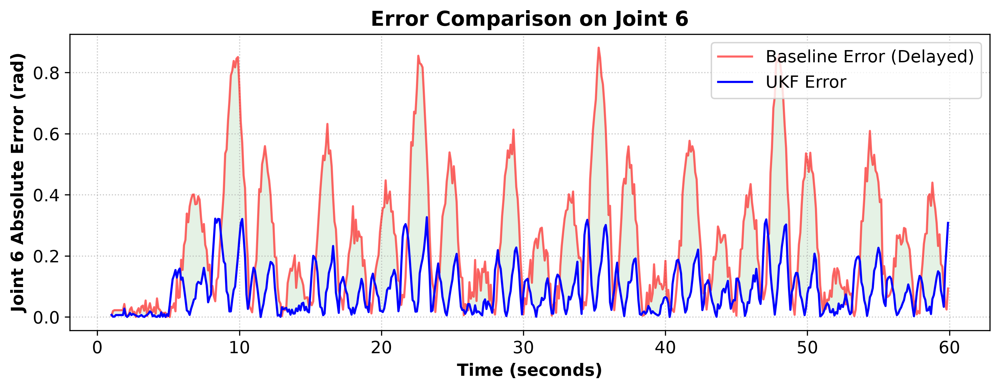

In [ ]:
# Call the function
traject_tracking("500", JOINT_NAMES[5])

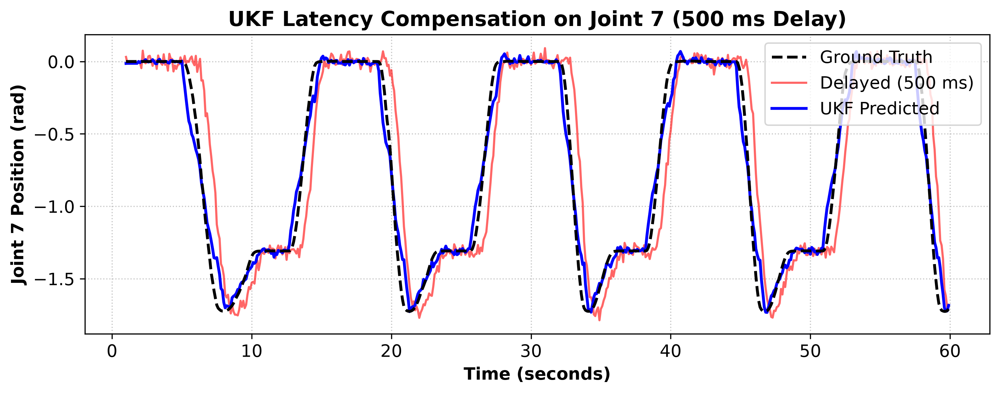

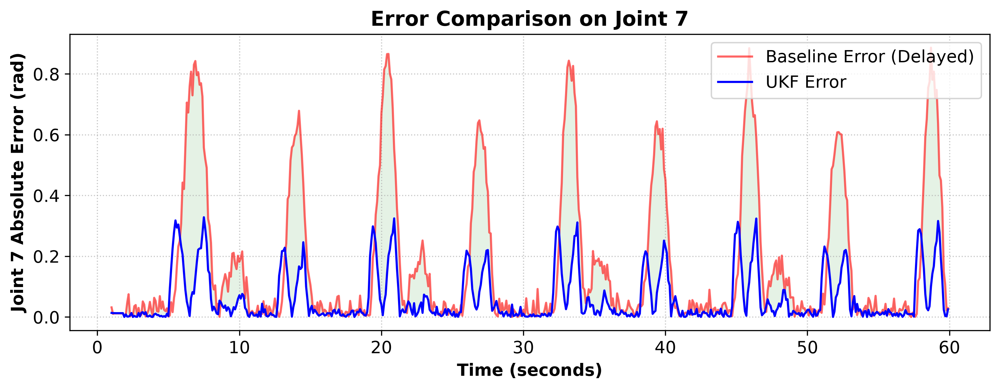

In [ ]:
# Call the function
traject_tracking("500", JOINT_NAMES[6])

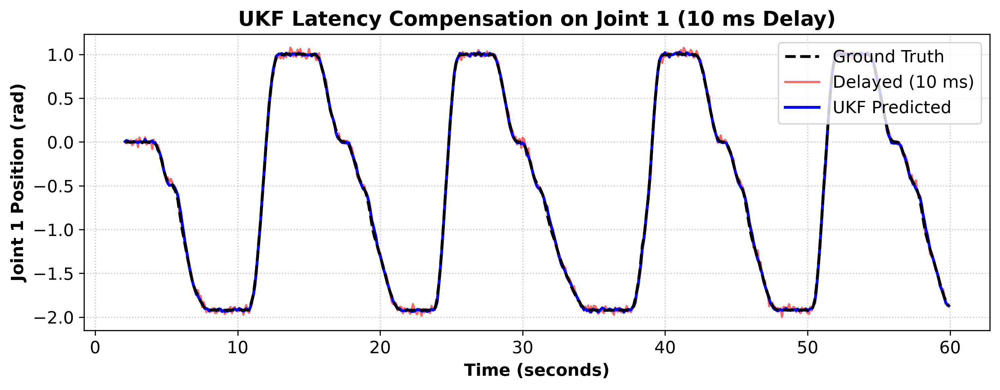

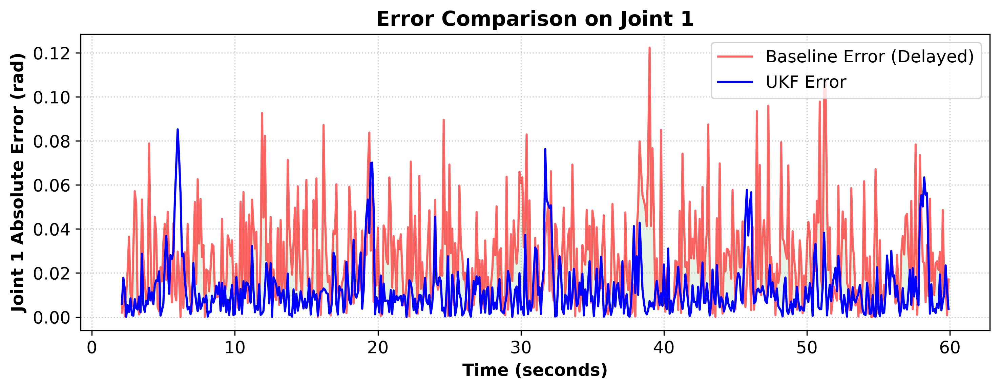

In [ ]:
# Call the function
traject_tracking("10", JOINT_NAMES[0])

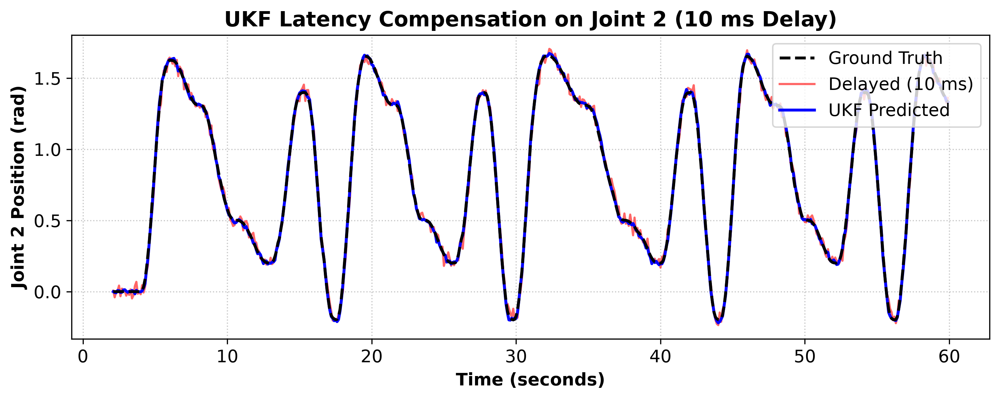

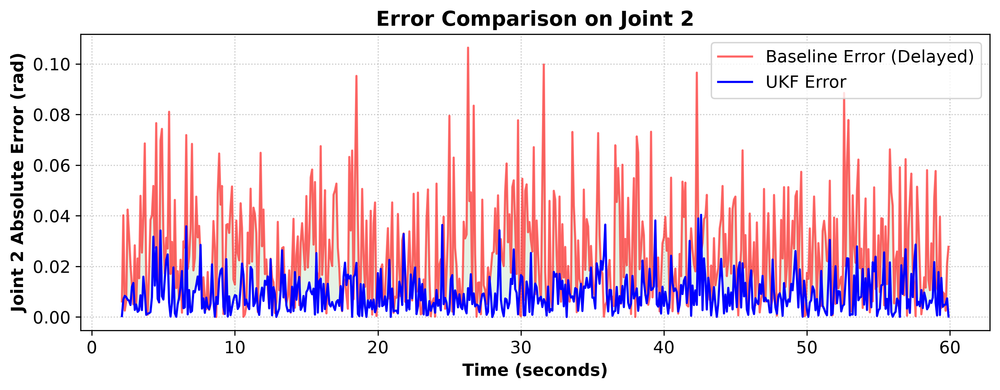

In [ ]:
# Call the function
traject_tracking("10", JOINT_NAMES[1])

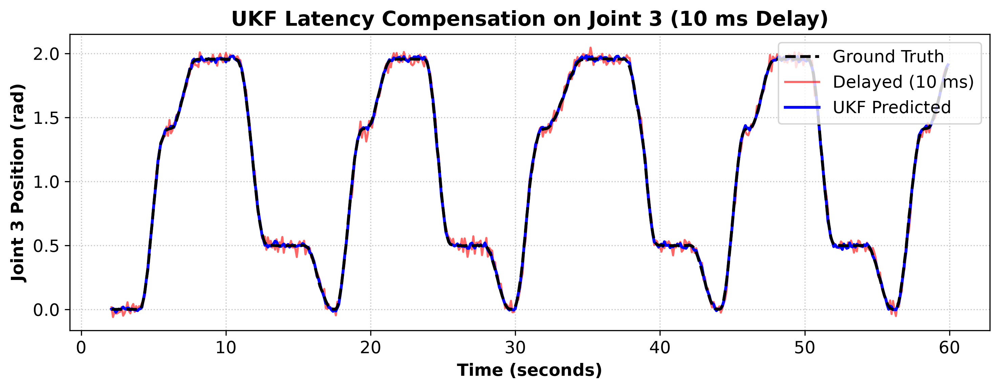

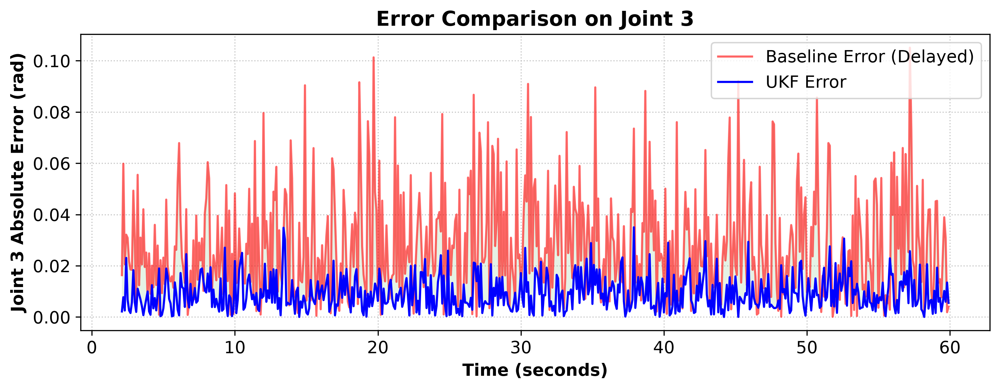

In [ ]:
# Call the function
traject_tracking("10", JOINT_NAMES[2])

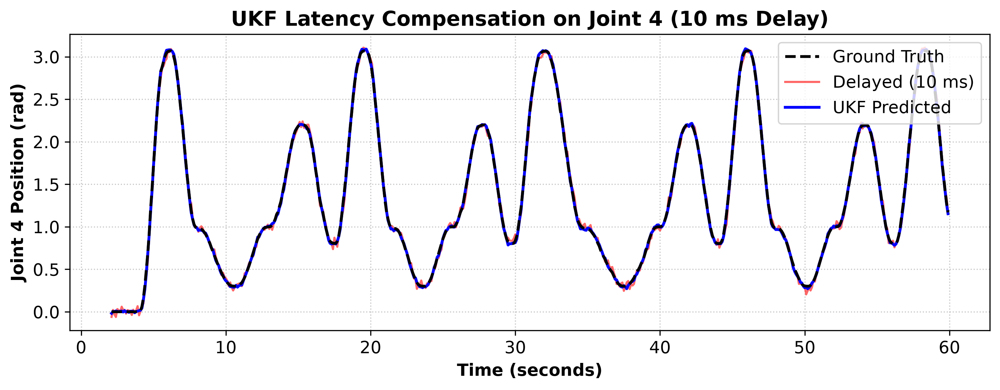

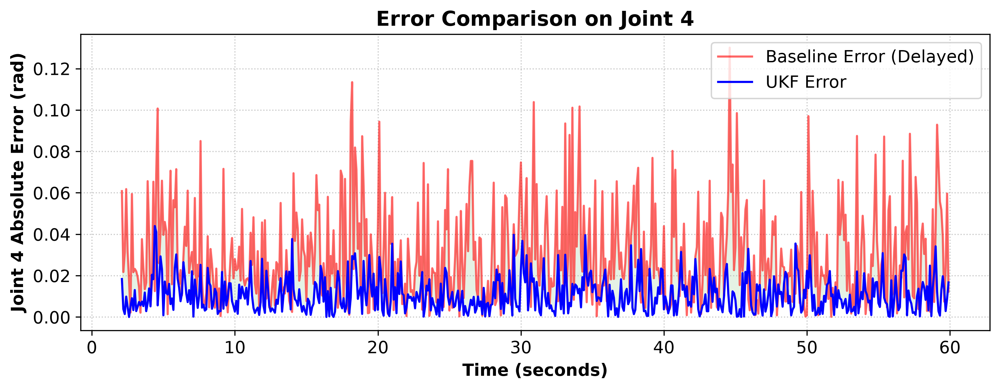

In [ ]:
# Call the function
traject_tracking("10", JOINT_NAMES[3])

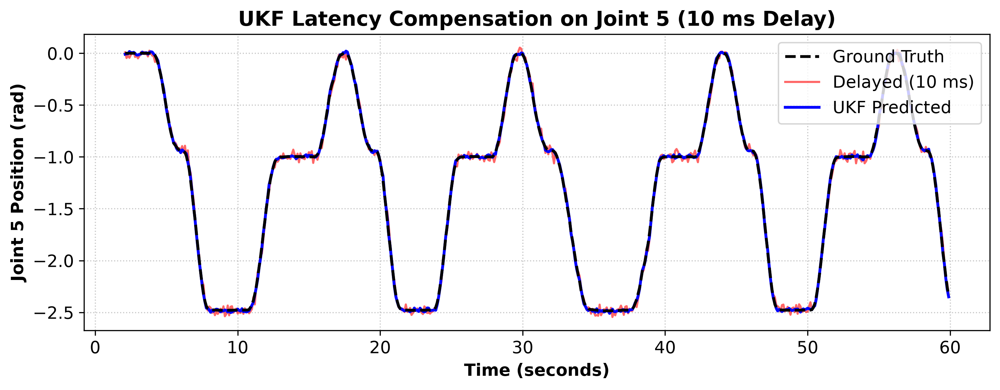

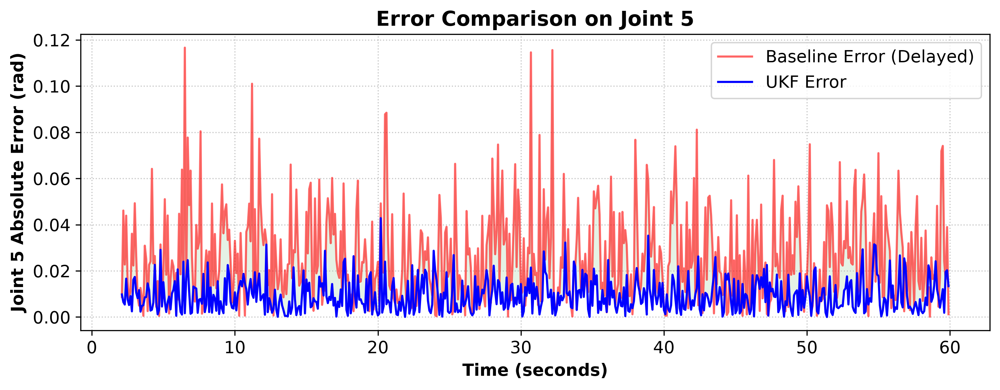

In [ ]:
# Call the function
traject_tracking("10", JOINT_NAMES[4])

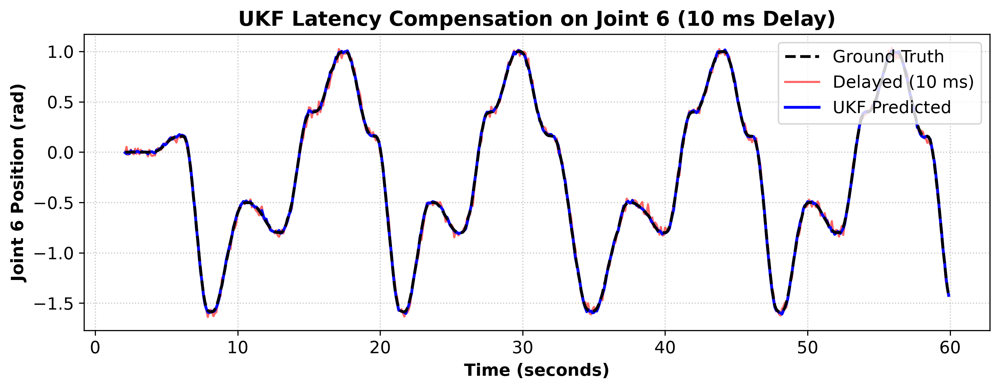

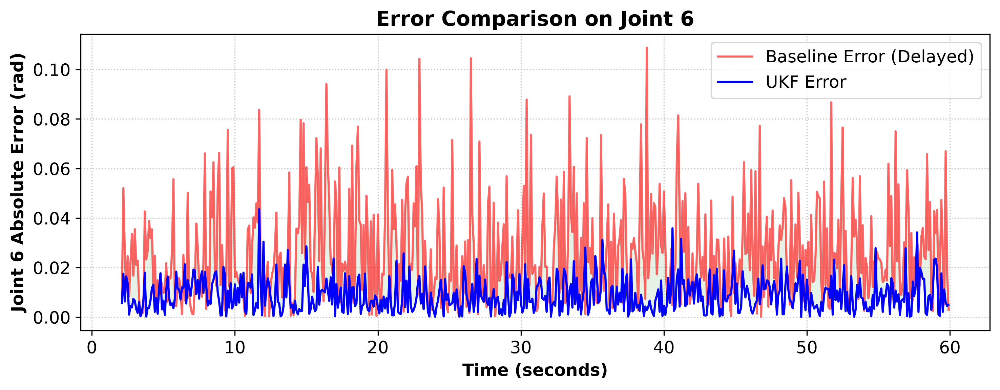

In [ ]:
# Call the function
traject_tracking("10", JOINT_NAMES[5])

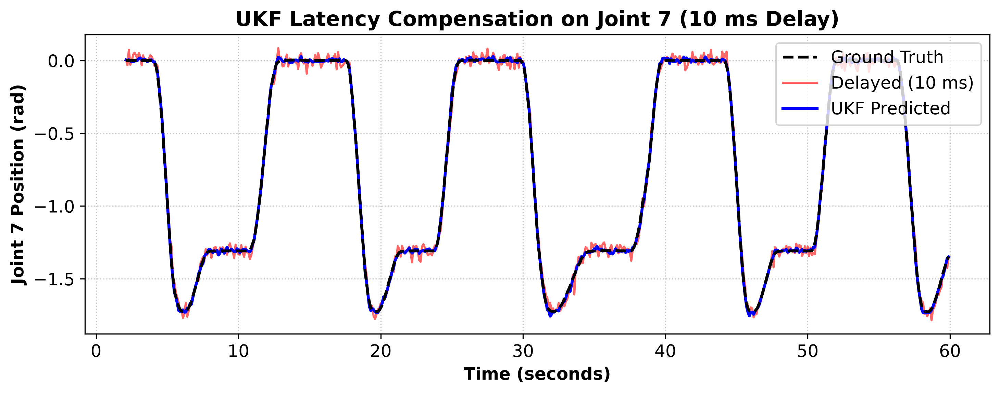

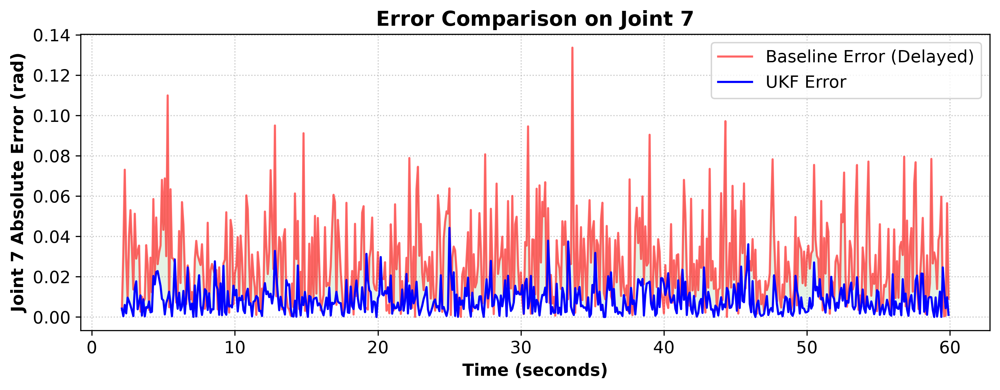

In [ ]:
# Call the function
traject_tracking("10", JOINT_NAMES[6])

In [ ]:
# Create the figure directory if it doesn't exist
os.makedirs('figure', exist_ok=True)

def save_journal_plots(delay_scenario, joint_name, save_filename):
    clean_joint_name = clean_NAMES.get(joint_name, joint_name) 
    file_path = f"UKF_timeseries_plot/{delay_scenario}ms.csv"

    # Load the data
    df = pd.read_csv(file_path)
    t = df['time_sec']
    true_pos = df[f'{joint_name}_true']
    del_pos = df[f'{joint_name}_delayed']
    pred_pos = df[f'{joint_name}_pred']

    # Calculate absolute errors
    error_baseline = np.abs(true_pos - del_pos)
    error_ukf = np.abs(true_pos - pred_pos)

    # Plotting Setup - Stacked 2x1 figure
    plt.rcParams.update({'font.size': 10, 'font.family': 'sans-serif'})
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), dpi=300, sharex=True) 

    # --- TOP PLOT: Trajectory Tracking ---
    ax1.plot(t, true_pos, label='Ground Truth', color='black', linestyle='--', linewidth=1.5, zorder=3)
    ax1.plot(t, del_pos, label=f'Delayed', color='red', alpha=0.6, linewidth=1.5)
    ax1.plot(t, pred_pos, label='UKF Predicted', color='blue', linewidth=1.5, zorder=2)
    
    ax1.set_ylabel(f'Position (rad)', fontweight='bold')
    ax1.legend(loc='upper right', fontsize=8)
    ax1.grid(True, linestyle=':', alpha=0.7)

    # --- BOTTOM PLOT: Absolute Error Comparison ---
    ax2.plot(t, error_baseline, label='Baseline Error', color='red', alpha=0.6, linewidth=1.5)
    ax2.plot(t, error_ukf, label='UKF Error', color='blue', linewidth=1.5)

    ax2.fill_between(t, error_ukf, error_baseline, where=(error_baseline > error_ukf), 
                    facecolor='green', alpha=0.2, interpolate=True, label='Error Reduced')

    ax2.set_xlabel('Time (seconds)', fontweight='bold')
    ax2.set_ylabel(f'Abs. Error (rad)', fontweight='bold')
    ax2.legend(loc='upper right', fontsize=8)
    ax2.grid(True, linestyle=':', alpha=0.7)

    plt.tight_layout()
    
    # SAVE THE FIGURE
    plt.savefig(f"figure/{save_filename}", format='pdf', bbox_inches='tight')
    plt.close(fig) # Closes the figure so it doesn't clutter your notebook output

# --- AUTOMATIC GENERATION LOOP ---
# List of (Delay, Joint_Name, Output_Filename)
scenarios_to_plot = [
    (300, 'base_link_to_link1', 'joint1_300ms.pdf'),
    (1100, 'base_link_to_link1', 'joint1_1100ms.pdf'),
    (300, 'link3_to_link4', 'joint4_300ms.pdf'),
    (1100, 'link3_to_link4', 'joint4_1100ms.pdf'),
    (300, 'link6_to_link7', 'joint7_300ms.pdf'),
    (1100, 'link6_to_link7', 'joint7_1100ms.pdf')
]

for delay, joint, filename in scenarios_to_plot:
    print(f"Generating {filename}...")
    save_journal_plots(delay, joint, filename)

print("All plots saved successfully in the 'figure' folder!")

Generating joint1_300ms.pdf...
Generating joint1_1100ms.pdf...
Generating joint4_300ms.pdf...
Generating joint4_1100ms.pdf...
Generating joint7_300ms.pdf...
Generating joint7_1100ms.pdf...
All plots saved successfully in the 'figures' folder!


In [ ]:
# save_path = f"{delay_scenario}_{joint_name}_analysis.png"
# plt.savefig(save_path, format='png', bbox_inches='tight')
# print(f"Plot saved successfully as: {save_path}")

# plt.show()